# Аудит и подготовка данных
**Датасет:** Airlines Delay (Kaggle, jimschacko).
**Задача:** бинарная классификация - по данным о рейсе предсказать, будет ли задержка (столбец `Delay`).
Одна строка - один рейс.

## 1 Загрузка данных и библиотек

In [ ]:
!pip install -q opendatasets legacy-cgi

In [ ]:
import opendatasets as od

od.download("https://www.kaggle.com/datasets/jimschacko/airlines-dataset-to-predict-a-delay")

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/airlines-dataset-to-predict-a-delay/Airlines.csv")
df.head()

,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
0,1,CO,269,SFO,IAH,3,15,205,1
1,2,US,1558,PHX,CLT,3,15,222,1
2,3,AA,2400,LAX,DFW,3,20,165,1
3,4,AA,2466,SFO,DFW,3,20,195,1
4,5,AS,108,ANC,SEA,3,30,202,0


## 2 Общая информация

In [3]:
df.shape

(539383, 9)

In [4]:
df.columns

Index(['id', 'Airline', 'Flight', 'AirportFrom', 'AirportTo', 'DayOfWeek',
       'Time', 'Length', 'Delay'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539383 entries, 0 to 539382
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   id           539383 non-null  int64 
 1   Airline      539383 non-null  object
 2   Flight       539383 non-null  int64 
 3   AirportFrom  539383 non-null  object
 4   AirportTo    539383 non-null  object
 5   DayOfWeek    539383 non-null  int64 
 6   Time         539383 non-null  int64 
 7   Length       539383 non-null  int64 
 8   Delay        539383 non-null  int64 
dtypes: int64(6), object(3)
memory usage: 37.0+ MB


In [6]:
df.describe()  # среднее, медиана, квартили, минимум и максимум

,id,Flight,DayOfWeek,Time,Length,Delay
count,539383.000000,539383.000000,539383.000000,539383.000000,539383.000000,539383.000000
mean,269692.000000,2427.928630,3.929668,802.728963,132.202007,0.445442
std,155706.604461,2067.429837,1.914664,278.045911,70.117016,0.497015
min,1.000000,1.000000,1.000000,10.000000,0.000000,0.000000
25%,134846.500000,712.000000,2.000000,565.000000,81.000000,0.000000
50%,269692.000000,1809.000000,4.000000,795.000000,115.000000,0.000000
75%,404537.500000,3745.000000,5.000000,1035.000000,162.000000,1.000000
max,539383.000000,7814.000000,7.000000,1439.000000,655.000000,1.000000


### Описание признаков
Перед проверками записал, что значит каждый столбец и какие у него должны быть значения.

| Поле | Смысл | Тип по смыслу | Правило |
|---|---|---|---|
| id | номер записи | целое | обязательное, уникальное |
| Airline | код авиакомпании | строка | 2 символа |
| Flight | номер рейса | строка (это номер, а не количество) | повторы допустимы |
| AirportFrom | аэропорт вылета | строка | 3 буквы |
| AirportTo | аэропорт прилёта | строка | 3 буквы, не совпадает с AirportFrom |
| DayOfWeek | день недели | категория | 1-7 |
| Time | время вылета, минуты от полуночи | целое | 0-1439 |
| Length | длительность полёта, мин | целое | больше 0 |
| Delay | задержка (целевая) | 0 / 1 | только 0 или 1 |

## 3 Типы данных
`Flight` и `DayOfWeek` загрузились как числа. Считать по ним среднее смысла нет: рейс 2000 не "больше" рейса 1000, а это просто номер. Тип поменяю в предобработке.

Проверяю, что коды авиакомпаний и аэропортов записаны одинаково: одна длина, нет лишних пробелов, всё заглавными.

In [7]:
for col in ["Airline", "AirportFrom", "AirportTo"]:
    s = df[col].astype("string")
    print(col)
    print("  длины кодов:", s.str.len().unique().tolist())
    print("  с пробелами по краям:", (s != s.str.strip()).sum())
    print("  не заглавными:", (s != s.str.upper()).sum())

Airline
  длины кодов: [2]


  с пробелами по краям: 0


  не заглавными: 0
AirportFrom
  длины кодов: [3]


  с пробелами по краям: 0


  не заглавными: 0
AirportTo
  длины кодов: [3]


  с пробелами по краям: 0


  не заглавными: 0


In [8]:
# в коде аэропорта должны быть только буквы
(~df["AirportFrom"].astype("string").str.isalpha()).sum(), (~df["AirportTo"].astype("string").str.isalpha()).sum()

(np.int64(0), np.int64(0))

In [9]:
df["Delay"].unique()

array([1, 0])

Форматы чистые: у авиакомпаний везде 2 символа, у аэропортов 3 буквы, лишних пробелов и строчных букв нет. В `Delay` только 0 и 1.

## 4 Пропущенные значения

In [10]:
df.isna().sum()  # количество пропусков по столбцам

id             0
Airline        0
Flight         0
AirportFrom    0
AirportTo      0
DayOfWeek      0
Time           0
Length         0
Delay          0
dtype: int64

In [11]:
(df.isna().mean() * 100).round(2)  # доля пропусков в процентах

id             0.0
Airline        0.0
Flight         0.0
AirportFrom    0.0
AirportTo      0.0
DayOfWeek      0.0
Time           0.0
Length         0.0
Delay          0.0
dtype: float64

Явных пропусков нет. Но пропуск может быть записан не как NaN, а особым значением, например пустой строкой или "?". Проверяю такие маркеры в строковых столбцах.

In [12]:
markers = ["", " ", "?", "nan", "NaN", "None", "NA", "-"]
df[["Airline", "AirportFrom", "AirportTo"]].isin(markers).sum()

Airline        0
AirportFrom    0
AirportTo      0
dtype: int64

Ещё один скрытый пропуск - ноль там, где ноля быть не может. Полёт не может длиться 0 минут.

In [13]:
df[df["Length"] == 0]

,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
179149,179150,F9,106,DEN,MSP,6,635,0,0
182840,182841,F9,107,MSP,DEN,6,851,0,0
188953,188954,F9,103,MSP,DEN,7,375,0,0
445578,445579,B6,493,BOS,SEA,7,1060,0,1


Нашлось 4 рейса с длительностью 0. Это не настоящий ноль, а скорее всего не записанное значение. Исправлю в предобработке.

На первом этапе я предполагал, что в данных будут пропуски во времени вылета. По факту их нет, проблема только в этих 4 строках.

## 5 Дубликаты

In [14]:
df.duplicated().sum()  # число полных копий сверх первого вхождения

np.int64(0)

In [15]:
df["id"].duplicated().sum()  # повторы ключа

np.int64(0)

Полных копий нет и `id` уникальный. Но `id` - это просто номер строки, поэтому проверяю повторы без него.

In [16]:
df.drop(columns="id").duplicated().sum()

np.int64(216618)

Без `id` совпадает больше 216 тысяч строк. Посмотрим, сколько раз повторяется одна и та же комбинация "авиакомпания, рейс, маршрут, день недели, время, длительность".

In [17]:
cols = ["Airline", "Flight", "AirportFrom", "AirportTo", "DayOfWeek", "Time", "Length"]
df.groupby(cols).size().value_counts().sort_index()

1     41941
2    106871
3     44239
4     20722
5     13619
Name: count, dtype: int64

In [18]:
# в скольких таких группах задержка была то есть, то нет
(df.groupby(cols)["Delay"].nunique() > 1).sum()

np.int64(95373)

Одна комбинация повторяется максимум 5 раз. В данных нет даты, есть только день недели. Получается, это один и тот же рейс по расписанию в разные недели (5 повторов как раз похоже на месяц). И в 95 тысячах групп рейс в одну неделю задержался, а в другую нет.

Это не дубли, а разные полёты, поэтому удалять их нельзя. Но есть риск: при делении на train и test один и тот же рейс может попасть в обе части. Это надо учесть на этапе обучения модели.

## 6 Уникальные значения и константные признаки

In [19]:
df.nunique()  # число уникальных непустых значений каждого столбца

id             539383
Airline            18
Flight           6585
AirportFrom       293
AirportTo         293
DayOfWeek           7
Time             1131
Length            426
Delay               2
dtype: int64

In [20]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]  # столбцы с одним значением или без значений

Series([], dtype: int64)

In [21]:
# аэропорты вылета и прилёта - один и тот же список?
set(df["AirportFrom"]) ^ set(df["AirportTo"])

set()

Константных столбцов нет. 18 авиакомпаний, 293 аэропорта, списки аэропортов вылета и прилёта совпадают.

## 7 Диапазоны
Проверяю правила из таблицы описания признаков.

In [22]:
rules = {
    "DayOfWeek вне 1-7": ~df["DayOfWeek"].between(1, 7),
    "Time вне 0-1439": ~df["Time"].between(0, 1439),
    "Length <= 0": df["Length"] <= 0,
    "Flight <= 0": df["Flight"] <= 0,
    "Delay не 0 и не 1": ~df["Delay"].isin([0, 1]),
}
pd.Series({name: mask.sum() for name, mask in rules.items()})

DayOfWeek вне 1-7    0
Time вне 0-1439      0
Length <= 0          4
Flight <= 0          0
Delay не 0 и не 1    0
dtype: int64

Нарушение одно - те же 4 рейса с нулевой длительностью.

## 8 Распределения числовых признаков и выбросы

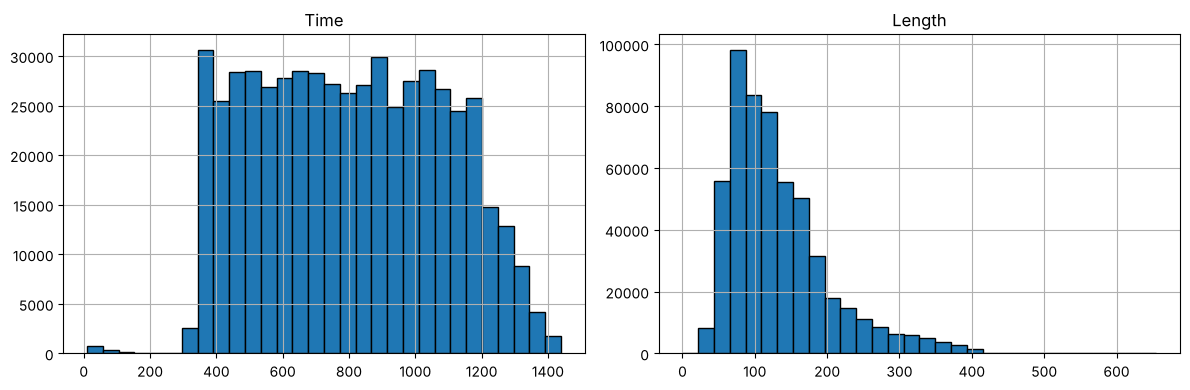

In [23]:
df[["Time", "Length"]].hist(bins=30, figsize=(12, 4), edgecolor="black")
plt.tight_layout()
plt.show()

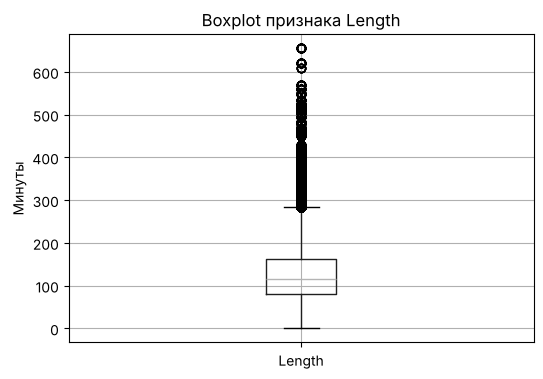

In [24]:
column = "Length"
df.boxplot(column=column, figsize=(6, 4))
plt.title(f"Boxplot признака {column}")
plt.ylabel("Минуты")
plt.show()

In [25]:
q1 = df["Length"].quantile(0.25)
q3 = df["Length"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print("Верхняя граница по IQR:", upper)
print("Рейсов выше границы:", (df["Length"] > upper).sum())

Верхняя граница по IQR: 283.5
Рейсов выше границы: 25650


In [26]:
# какие маршруты дают эти выбросы
df[df["Length"] > upper].groupby(["AirportFrom", "AirportTo"]).size().sort_values(ascending=False).head(10)

AirportFrom  AirportTo
LAX          JFK          812
JFK          LAX          812
SFO          JFK          554
JFK          SFO          554
LAX          HNL          460
HNL          LAX          459
ATL          LAX          441
IAD          LAX          331
ORD          SFO          325
JFK          LAS          301
dtype: int64

По IQR выбросов около 25 тысяч, это рейсы дольше 283 минут. Но это реальные дальние перелёты: Лос-Анджелес - Нью-Йорк, Сан-Франциско - Нью-Йорк, рейсы на Гавайи. Статистическая редкость тут не значит ошибку, поэтому их оставляю.

## 9 Согласованность
Аэропорт вылета не должен совпадать с аэропортом прилёта.

In [27]:
(df["AirportFrom"] == df["AirportTo"]).sum()

np.int64(0)

Второе правило: на одном и том же маршруте длительность полёта должна быть примерно одинаковой. Сравниваю каждый рейс с медианой своего маршрута. Подозрительным считаю рейс, который в 2 раза дольше или в 2 раза короче обычного.

In [28]:
route_median = df.groupby(["AirportFrom", "AirportTo"])["Length"].transform("median")
suspect = ((df["Length"] > 2 * route_median) | (df["Length"] < 0.5 * route_median)) & (df["Length"] > 0)
print("Подозрительных рейсов (без нулевых):", suspect.sum())
df[suspect].assign(route_median=route_median[suspect])

Подозрительных рейсов (без нулевых): 10


,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay,route_median
21484,21485,OO,6939,PDX,SEA,4,530,179,0,50.0
73160,73161,OO,4681,IDA,SLC,7,640,23,1,57.0
74315,74316,OO,4855,BIL,SLC,7,700,170,1,82.0
161671,161672,HA,168,HNL,KOA,5,625,155,1,43.0
177197,177198,OO,7767,RKS,SLC,6,520,30,0,67.0
311884,311885,OO,7767,GCC,RKS,7,372,159,0,77.0
329564,329565,OO,7767,GCC,RKS,1,372,159,1,77.0
416700,416701,OO,7812,SLC,RKS,5,1190,133,0,59.0
430796,430797,OO,7812,SLC,RKS,6,1190,133,1,59.0
432620,432621,OO,7767,GCC,RKS,7,372,159,0,77.0


Таких рейсов 10, почти все у авиакомпании OO. Например, HNL - KOA обычно летит 43 минуты, а тут 155. Возможно, рейс с промежуточной посадкой, возможно ошибка. Без источника не проверить. Строк мало, поэтому не удаляю, а ставлю флаг.

## 10 Баланс классов

In [29]:
df["Delay"].value_counts(dropna=False)  # количество объектов, включая пропуски

Delay
0    299119
1    240264
Name: count, dtype: int64

In [30]:
(df["Delay"].value_counts(normalize=True) * 100).round(2)

Delay
0    55.46
1    44.54
Name: proportion, dtype: float64

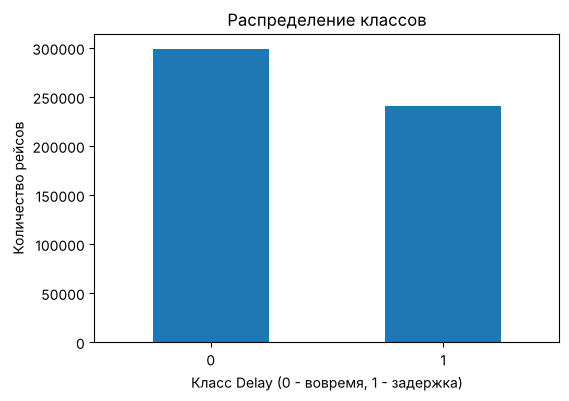

In [31]:
df["Delay"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Распределение классов")
plt.xlabel("Класс Delay (0 - вовремя, 1 - задержка)")
plt.ylabel("Количество рейсов")
plt.xticks(rotation=0)
plt.show()

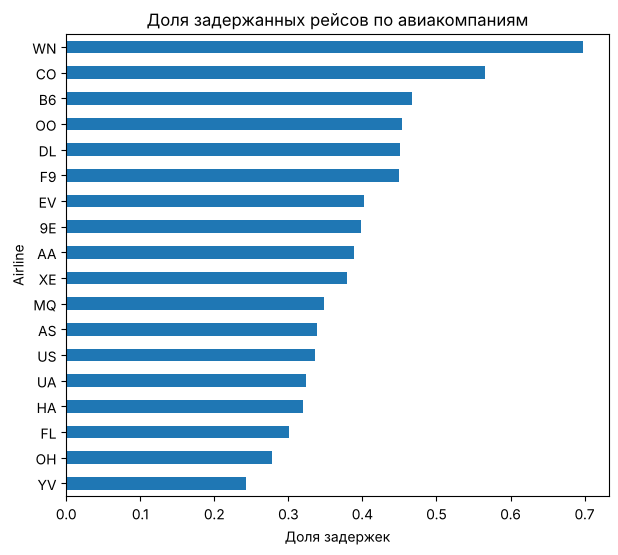

In [32]:
# доля задержек по авиакомпаниям
delay_by_airline = df.groupby("Airline")["Delay"].mean().sort_values()
delay_by_airline.plot(kind="barh", figsize=(7, 6))
plt.title("Доля задержанных рейсов по авиакомпаниям")
plt.xlabel("Доля задержек")
plt.show()

Классы почти сбалансированы: 55,5% вовремя и 44,5% с задержкой. Если модель всем рейсам ответит "задержки не будет", она уже угадает 55,5%. Значит, нормальная модель должна быть заметно лучше этого числа, и смотреть надо не только на accuracy, но и на precision и recall по классу 1.

По авиакомпаниям разница большая: у WN задерживается почти 70% рейсов, у YV около 24%. Авиакомпания точно будет полезным признаком.

## 11 Профиль качества
Собираю все проверки в одну таблицу.

In [33]:
n = len(df)
dup_no_id = df.drop(columns="id").duplicated().sum()

profile = pd.DataFrame([
    ["Пропуски (NaN) во всех столбцах", df.isna().sum().sum(), n * df.shape[1]],
    ["Особые маркеры пропуска в строках", df[["Airline", "AirportFrom", "AirportTo"]].isin(markers).sum().sum(), n * 3],
    ["Length = 0", (df["Length"] == 0).sum(), n],
    ["Length сильно отличается от медианы маршрута", suspect.sum(), n],
    ["Length выше границы IQR (дальние рейсы)", (df["Length"] > upper).sum(), n],
    ["Полные копии строк", df.duplicated().sum(), n],
    ["Повтор всех полей, кроме id", dup_no_id, n],
    ["AirportFrom = AirportTo", (df["AirportFrom"] == df["AirportTo"]).sum(), n],
    ["DayOfWeek или Time вне диапазона", (rules["DayOfWeek вне 1-7"] | rules["Time вне 0-1439"]).sum(), n],
    ["Рейсы с задержкой (Delay = 1)", (df["Delay"] == 1).sum(), n],
], columns=["Проверка", "Число", "База"])

profile["Доля, %"] = (profile["Число"] / profile["База"] * 100).round(3)
profile

,Проверка,Число,База,"Доля, %"
0,Пропуски (NaN) во всех столбцах,0,4854447,0.000
1,Особые маркеры пропуска в строках,0,1618149,0.000
2,Length = 0,4,539383,0.001
3,Length сильно отличается от медианы маршрута,10,539383,0.002
4,Length выше границы IQR (дальние рейсы),25650,539383,4.755
5,Полные копии строк,0,539383,0.000
6,"Повтор всех полей, кроме id",216618,539383,40.160
7,AirportFrom = AirportTo,0,539383,0.000
8,DayOfWeek или Time вне диапазона,0,539383,0.000
9,Рейсы с задержкой (Delay = 1),240264,539383,44.544


Нарушения могут пересекаться, поэтому проценты нельзя складывать в общую долю плохих строк.

**Приоритеты:**

| Приоритет | Что нашёл | Решение |
|---|---|---|
| Блокирует расчёт | ничего | - |
| Требует уточнения | 4 рейса с Length = 0, 10 рейсов с нетипичной длительностью | нули заменить медианой маршрута, остальные пометить флагом |
| Допустимо с условием | повторы рейсов без даты | не удалять, учесть при делении на train/test |

## 12 Краткий итог аудита

In [34]:
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Полных копий:", df.duplicated().sum())
print("Нулевая длительность:", (df["Length"] == 0).sum())
print("Доля задержек, %:", round(df["Delay"].mean() * 100, 2))

Количество строк: 539383
Количество столбцов: 9
Пропущенных ячеек: 0


Полных копий: 0
Нулевая длительность: 4
Доля задержек, %: 44.54


## 13 Предобработка данных
Работаю с копией, исходный `df` не трогаю.

In [35]:
df_clean = df.copy()

**Нулевая длительность.** Меняю 0 на NaN, а потом заполняю медианой своего маршрута. Отдельным столбцом отмечаю, какие строки исправлены.

In [36]:
df_clean["length_fixed"] = (df_clean["Length"] == 0).astype(int)
df_clean.loc[df_clean["Length"] == 0, "Length"] = np.nan

route_median_clean = df_clean.groupby(["AirportFrom", "AirportTo"])["Length"].transform("median")
df_clean["Length"] = df_clean["Length"].fillna(route_median_clean).astype(int)

df_clean[df_clean["length_fixed"] == 1]

,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay,length_fixed
179149,179150,F9,106,DEN,MSP,6,635,120,0,1
182840,182841,F9,107,MSP,DEN,6,851,131,0,1
188953,188954,F9,103,MSP,DEN,7,375,131,0,1
445578,445579,B6,493,BOS,SEA,7,1060,377,1,1


**Флаг подозрительной длительности.** Строки не удаляю, просто помечаю.

In [37]:
df_clean["length_suspect"] = suspect.astype(int)
df_clean["length_suspect"].sum()

np.int64(10)

**Типы данных.** Номер рейса делаю строкой, коды - категориями, день недели - упорядоченной категорией.

In [38]:
memory_before = df_clean.memory_usage(deep=True).sum() / 1024**2

df_clean["Flight"] = df_clean["Flight"].astype("string")
for col in ["Airline", "AirportFrom", "AirportTo"]:
    df_clean[col] = df_clean[col].astype("category")

df_clean["DayOfWeek"] = pd.Categorical(df_clean["DayOfWeek"], categories=[1, 2, 3, 4, 5, 6, 7], ordered=True)

memory_after = df_clean.memory_usage(deep=True).sum() / 1024**2
print(f"Память до: {memory_before:.1f} МБ, после: {memory_after:.1f} МБ")
df_clean.dtypes

Память до: 112.7 МБ, после: 54.9 МБ


id                         int64
Airline                 category
Flight            string[python]
AirportFrom             category
AirportTo               category
DayOfWeek               category
Time                       int64
Length                     int64
Delay                      int64
length_fixed               int64
length_suspect             int64
dtype: object

**Часть суток.** Время вылета в минутах удобно разбить на интервалы через `pd.cut`.

In [39]:
df_clean["DayPart"] = pd.cut(
    df_clean["Time"],
    bins=[0, 360, 720, 1080, 1440],
    labels=["Ночь", "Утро", "День", "Вечер"],
    right=False
)
df_clean.groupby("DayPart", observed=True)["Delay"].agg(["mean", "size"])

,mean,size
DayPart,,
Ночь,0.279307,6176
Утро,0.363577,218449
День,0.500913,206930
Вечер,0.514356,107828


Чем позже вылет, тем чаще задержка: ночью около 28%, вечером уже 51%. Скорее всего, задержки за день накапливаются.

### Повторная проверка после исправлений

In [40]:
print("Пропусков:", df_clean.isna().sum().sum())
print("Length <= 0:", (df_clean["Length"] <= 0).sum())
print("Строк:", len(df_clean), "(было", len(df), ")")
print("Доля задержек, %:", round(df_clean["Delay"].mean() * 100, 2))

Пропусков: 0
Length <= 0: 0
Строк: 539383 (было 539383 )
Доля задержек, %: 44.54


In [41]:
df_clean.head()

,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay,length_fixed,length_suspect,DayPart
0,1,CO,269,SFO,IAH,3,15,205,1,0,0,Ночь
1,2,US,1558,PHX,CLT,3,15,222,1,0,0,Ночь
2,3,AA,2400,LAX,DFW,3,20,165,1,0,0,Ночь
3,4,AA,2466,SFO,DFW,3,20,195,1,0,0,Ночь
4,5,AS,108,ANC,SEA,3,30,202,0,0,0,Ночь


In [42]:
df_clean.to_csv("airlines_clean.csv", index=False)

## 14 Выводы
- В датасете 539 383 рейса и 9 столбцов. Явных пропусков и полных копий нет.
- Нашёл 4 скрытых пропуска: длительность полёта 0 минут. Заменил медианой маршрута и пометил флагом `length_fixed`.
- 10 рейсов летят в 2 раза дольше или короче обычного для своего маршрута. Оставил, поставил флаг `length_suspect`.
- Выбросы по IQR - это настоящие дальние рейсы, их не трогал.
- 216 тысяч строк совпадают во всём, кроме id. Это один рейс в разные недели, в данных просто нет даты. Удалять нельзя, но при обучении надо следить, чтобы один рейс не попал и в train, и в test.
- Классы почти сбалансированы (55,5% / 44,5%), модель должна быть лучше 55,5% accuracy.
- Поменял типы: Flight в строку, коды в category, день недели в упорядоченную категорию. Добавил часть суток `DayPart`.
- Данные пригодны для задачи классификации, очищенная версия сохранена в `airlines_clean.csv`.